# Spotify Musical Eras / Clustering

## Objective
Find interpretable audio-feature groups, visualize their geometry with PCA, and assess whether they align with release decades without assuming that clusters are true musical eras.

## Dataset overview
The source is Yamac Eren Ay's [Spotify Dataset 1921–2020, 600k+ Tracks](https://www.kaggle.com/datasets/yamaerenay/spotify-dataset-19212020-600k-tracks), version 1.
The actual release-year range is audited below rather than inferred from the title. This is a historical catalog snapshot with track metadata, Spotify audio descriptors, and popularity (0–100). It has no track-level genre, album, listener histories, or contemporaneous chart labels.

Run `python scripts/download_data.py` and `python scripts/prepare_data.py` first. Every notebook runs independently from the project root. Source hashes and cleaning counts live in `data/processed/quality_report.json`.

## Imports

In [1]:
from pathlib import Path
import json
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RANDOM_STATE = 42
ROOT = Path.cwd()
if not (ROOT / "scripts/prepare_data.py").exists():
    raise RuntimeError("Open Jupyter from the project root.")
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
pd.set_option("display.max_columns", 15)
assert Path(sys.prefix).name == "spotify", "Select the Python (spotify) kernel."
display(Markdown(f"**Runtime:** Python {platform.python_version()} · spotify environment"))
AUDIO_FEATURES = ["danceability", "energy", "valence", "acousticness",
                  "instrumentalness", "speechiness", "liveness", "loudness", "tempo"]

**Runtime:** Python 3.14.7 · spotify environment

## Data loading and cleaning

In [2]:
tracks = pd.read_parquet(ROOT / "data/processed/tracks.parquet")
quality = json.loads((ROOT / "data/processed/quality_report.json").read_text())
display(pd.Series({"raw_rows": quality["raw_rows"],
                   "processed_rows": len(tracks),
                   "first_year": quality["year_min"], "last_year": quality["year_max"],
                   "repeated_artist_title_rows": quality["repeated_artist_title_rows"]}, name="Data audit"))
assert tracks.id.is_unique

raw_rows                      586672
processed_rows                586601
first_year                      1900
last_year                       2021
repeated_artist_title_rows     62393
Name: Data audit, dtype: int64

Shared preparation removes exact duplicates and repeated Spotify IDs, and drops rows without usable identity. Invalid numeric values become missing; unknown zero tempo becomes missing. Dates keep their original precision in `release_date`, with a derived year for grouping. Long recordings are flagged, not arbitrarily deleted. Unicode names are retained. Distinct IDs with the same artist/title remain in the shared data because editions can differ; modeling and recommendation apply stricter deduplication below. Unobserved recordings cannot be identified without acoustic fingerprints.

## Feature engineering and preprocessing
Use nine continuous audio descriptors. Exclude popularity, artist identity, and year so cluster interpretation against eras is not circular. Duration is omitted because spoken chapters and long recordings can dominate distance. Keep one artist/title edition, then take a seeded 30,000-track sample for practical laptop execution. Median imputation retains tracks with an unknown tempo. Standardization subtracts the mean and divides by the standard deviation so BPM and loudness do not overwhelm features on a 0–1 scale. This is descriptive unsupervised fitting; there is no predictive test set here.

In [3]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from threadpoolctl import threadpool_limits

catalog = tracks.drop_duplicates("recording_group")
sample = catalog.sample(n=min(30000, len(catalog)), random_state=42).copy()
preprocessor = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
scaled = preprocessor.fit_transform(sample[AUDIO_FEATURES])
display(sample[AUDIO_FEATURES].corr().round(2))

,danceability,energy,valence,acousticness,instrumentalness,speechiness,liveness,loudness,tempo
danceability,1.00,0.24,0.53,-0.24,-0.22,0.20,-0.09,0.24,-0.04
energy,0.24,1.00,0.37,-0.71,-0.19,-0.06,0.13,0.77,0.23
valence,0.53,0.37,1.00,-0.18,-0.17,0.04,0.01,0.27,0.13
acousticness,-0.24,-0.71,-0.18,1.00,0.20,0.07,-0.00,-0.52,-0.20
instrumentalness,-0.22,-0.19,-0.17,0.20,1.00,-0.11,-0.05,-0.32,-0.05
speechiness,0.20,-0.06,0.04,0.07,-0.11,1.00,0.22,-0.18,-0.10
liveness,-0.09,0.13,0.01,-0.00,-0.05,0.22,1.00,0.03,-0.02
loudness,0.24,0.77,0.27,-0.52,-0.32,-0.18,0.03,1.00,0.19
tempo,-0.04,0.23,0.13,-0.20,-0.05,-0.10,-0.02,0.19,1.00


Correlated descriptors, such as energy and loudness, implicitly give some musical dimensions more weight. Standardization equalizes marginal scales, not conceptual importance. Speech and instrumental recordings can form distinct groups in this mixed catalog.

## PCA methodology
Principal component analysis rotates standardized features into uncorrelated directions ordered by variance. The cumulative explained-variance curve describes how much information a reduced representation retains. PCA is used for visualization; K-Means uses all nine standardized features. Loadings identify which descriptors contribute to each direction; their signs can flip without changing the solution.

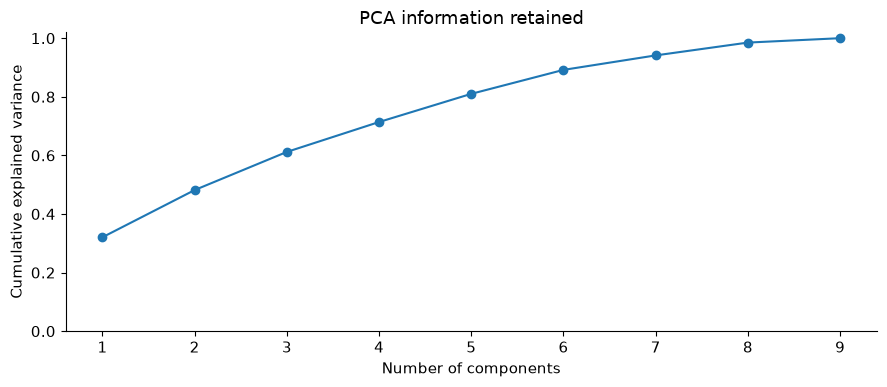

,PC1 loading,PC2 loading
danceability,0.296,0.504
energy,0.520,-0.150
valence,0.332,0.341
acousticness,-0.445,0.184
instrumentalness,-0.250,-0.235
speechiness,-0.033,0.599
liveness,0.031,0.184
loudness,0.485,-0.189
tempo,0.183,-0.300


The first two components retain **48.2%** of standardized variance. Overlap in a 2D plot can hide separation in later components.

In [4]:
pca = PCA()
coordinates = pca.fit_transform(scaled)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, len(AUDIO_FEATURES)+1), np.cumsum(pca.explained_variance_ratio_), marker="o")
ax.set(title="PCA information retained", xlabel="Number of components", ylabel="Cumulative explained variance", ylim=(0, 1.02))
plt.tight_layout()
plt.show()
display(pd.DataFrame(pca.components_[:2].T, index=AUDIO_FEATURES, columns=["PC1 loading", "PC2 loading"]).round(3))
display(Markdown(f"The first two components retain **{pca.explained_variance_ratio_[:2].sum():.1%}** of standardized variance. Overlap in a 2D plot can hide separation in later components."))

## K-Means and cluster selection
K-Means minimizes within-cluster squared Euclidean distances to centroids. Inertia always falls as clusters are added; an elbow suggests diminishing returns. Silhouette compares a point's cohesion with separation from its nearest alternative cluster (−1 to 1). We compare 2–8 clusters and choose the highest silhouette on the same seeded 2,000-track subset. Ten initializations reduce sensitivity to starting centroids. This is a heuristic for compact groups, not evidence of a true number of genres.

,clusters,inertia,silhouette
0,2,210600.105,0.235
1,3,182003.796,0.254
2,4,162393.117,0.224
3,5,146348.882,0.196
4,6,134172.041,0.199
5,7,126035.169,0.200
6,8,118292.519,0.182


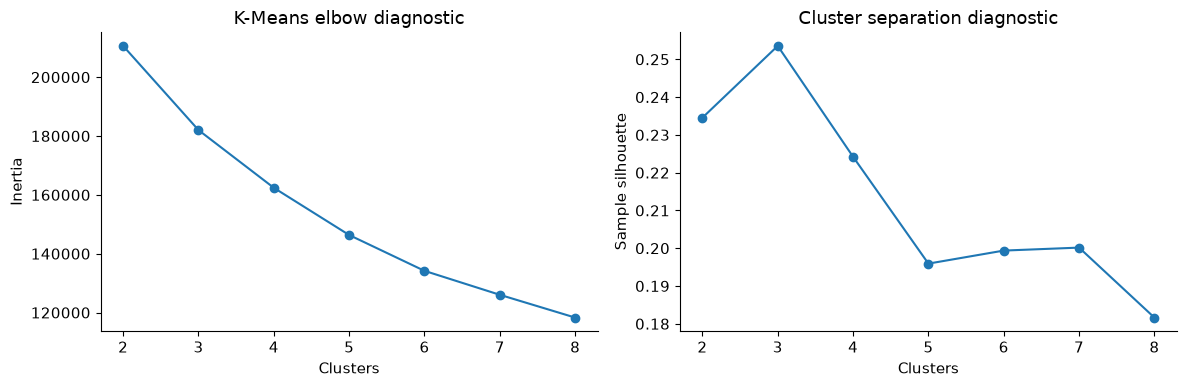

In [5]:
cluster_models = {}
diagnostics = []
with threadpool_limits(limits=4):
    for cluster_count in range(2, 9):
        model = KMeans(n_clusters=cluster_count, n_init=10, random_state=42)
        labels = model.fit_predict(scaled)
        score = silhouette_score(scaled, labels, sample_size=2000, random_state=42)
        cluster_models[cluster_count] = model
        diagnostics.append({"clusters": cluster_count, "inertia": model.inertia_, "silhouette": score})
diagnostics = pd.DataFrame(diagnostics)
best_k = int(diagnostics.loc[diagnostics.silhouette.idxmax(), "clusters"])
sample["cluster"] = cluster_models[best_k].labels_
display(diagnostics.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(diagnostics.clusters, diagnostics.inertia, marker="o")
axes[0].set(title="K-Means elbow diagnostic", xlabel="Clusters", ylabel="Inertia")
axes[1].plot(diagnostics.clusters, diagnostics.silhouette, marker="o")
axes[1].set(title="Cluster separation diagnostic", xlabel="Clusters", ylabel="Sample silhouette")
plt.tight_layout()
plt.show()

## Results: geometry and musical profiles

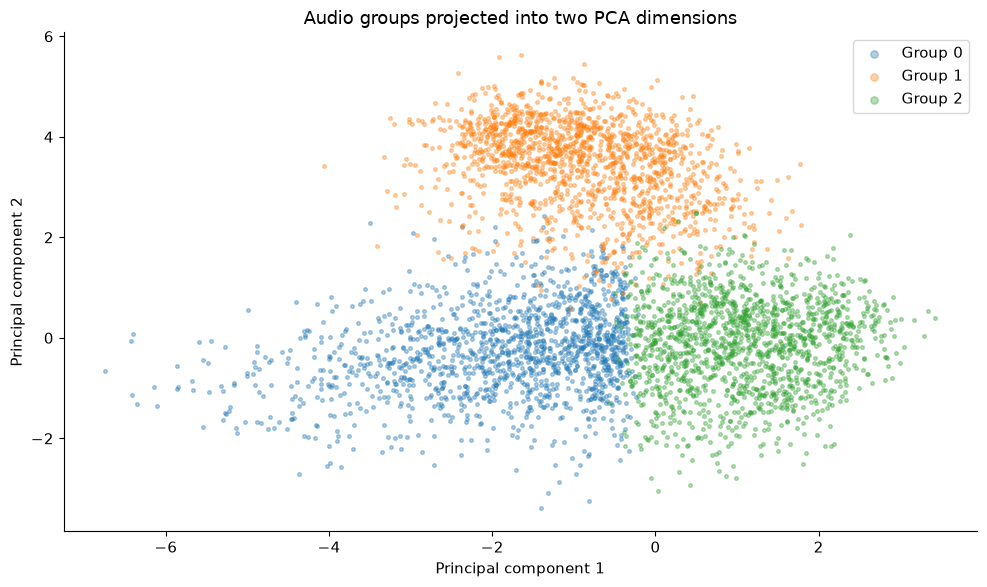

,danceability,energy,valence,acousticness,instrumentalness,speechiness,liveness,loudness,tempo
cluster,,,,,,,,,
0,0.467,0.283,0.359,0.851,0.001,0.039,0.125,-13.436,106.605
1,0.676,0.371,0.574,0.673,0.000,0.924,0.340,-15.131,96.978
2,0.623,0.698,0.673,0.172,0.000,0.047,0.142,-7.267,122.998


cluster
0    10162
1     1543
2    18295
Name: Tracks in sample, dtype: int64

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
for cluster in range(best_k):
    members = np.flatnonzero(sample.cluster.to_numpy() == cluster)[:1500]
    ax.scatter(coordinates[members, 0], coordinates[members, 1], s=7, alpha=0.35, label=f"Group {cluster}")
ax.set(title="Audio groups projected into two PCA dimensions", xlabel="Principal component 1", ylabel="Principal component 2")
ax.legend(markerscale=2)
plt.tight_layout()
fig.savefig(REPORTS / "02_clusters.png", dpi=120)
plt.show()
profiles = sample.groupby("cluster")[AUDIO_FEATURES].median()
display(profiles.round(3))
display(sample.groupby("cluster").size().rename("Tracks in sample"))

In this pinned run, group 0 is relatively acoustic and low-energy (median acousticness 0.851, energy 0.283); group 1 is dominated by speech-like content (speechiness 0.924); group 2 is louder and more energetic (energy 0.698, loudness −7.267 dB). This shows why a music catalog cannot be assumed to contain only songs. PC1 contrasts energy/loudness with acousticness, while PC2 emphasizes speechiness and danceability. Group numbers are arbitrary. The scatter is capped at 1,500 points per group for legibility, so apparent point density is not group size.

decade
1900       1
1920     402
1930     688
1940     866
1950    1827
1960    2558
1970    3160
1980    4276
1990    5529
2000    4178
2010    5493
2020    1022
Name: Sampled tracks per decade, dtype: int64

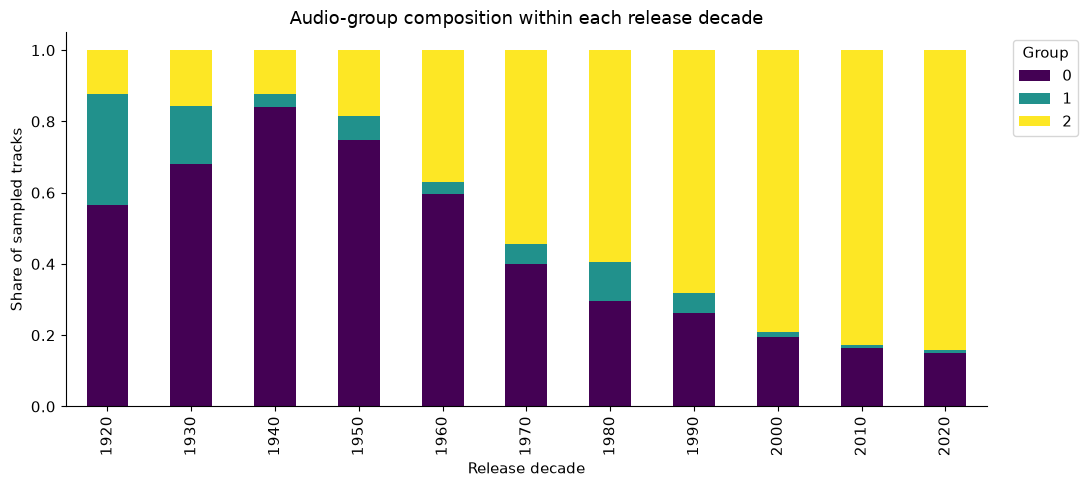

**Selected solution:** 3 groups; silhouette **0.254**. Agreement across two initialization seeds is **0.999** (adjusted Rand index; 1 means identical partitions). Decade/group normalized mutual information is **0.078** (0 means no shared information; 1 means equivalent partitions). Seed agreement is not evidence of stability under resampling or a different feature set.

In [7]:
era_shares = pd.crosstab(sample.decade, sample.cluster, normalize="index")
era_counts = sample.groupby("decade").size()
display(era_counts.rename("Sampled tracks per decade"))
era_shares = era_shares.loc[era_counts >= 100]
ax = era_shares.plot.bar(stacked=True, figsize=(11, 5), colormap="viridis")
ax.set(title="Audio-group composition within each release decade", xlabel="Release decade", ylabel="Share of sampled tracks")
ax.legend(title="Group", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()
known_eras = sample.decade.notna()
era_agreement = normalized_mutual_info_score(sample.loc[known_eras, "decade"].astype(str), sample.loc[known_eras, "cluster"])
with threadpool_limits(limits=4):
    alternative = KMeans(n_clusters=best_k, n_init=10, random_state=43).fit_predict(scaled)
stability = adjusted_rand_score(sample.cluster, alternative)
summary = {"sample_rows": len(sample), "clusters": best_k,
           "silhouette": float(diagnostics.silhouette.max()),
           "pca_two_component_variance": float(pca.explained_variance_ratio_[:2].sum()),
           "seed_stability_ari": float(stability), "decade_nmi": float(era_agreement)}
(REPORTS / "clustering_metrics.json").write_text(json.dumps(summary, indent=2))
display(Markdown(f"**Selected solution:** {best_k} groups; silhouette **{summary['silhouette']:.3f}**. Agreement across two initialization seeds is **{stability:.3f}** (adjusted Rand index; 1 means identical partitions). Decade/group normalized mutual information is **{era_agreement:.3f}** (0 means no shared information; 1 means equivalent partitions). Seed agreement is not evidence of stability under resampling or a different feature set."))

## Interpretation, limitations, and conclusion
The decade chart excludes groups with fewer than 100 sampled tracks; the counts remain visible above. The 2020s cover only 2020–2021. Acoustic/low-energy recordings account for more of the earlier decades, while louder/energetic recordings account for more of the later ones.

The profiles describe broad audio tendencies; the stacked chart tests era alignment after fitting. Decades can share multiple profiles, and changing mixtures do not establish distinct eras. Silhouette favors convex separated groups and can select coarse partitions. PCA discards information, the sample is not population-representative, and correlated descriptors influence distance. The initialization check assesses one source of instability only. Resampling, alternative scalings, and richer metadata are useful next steps before assigning musical labels.